## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import cv2
import time
import json
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Deep Learning Libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical, plot_model

# Scikit-learn for metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Set style for publication-quality plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("paper", font_scale=1.5)

print("✓ Libraries imported successfully")
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {len(tf.config.list_physical_devices('GPU'))} device(s)")


✓ Libraries imported successfully
TensorFlow Version: 2.15.0
GPU Available: 0 device(s)


## 2. Configuration and Hyperparameters

In [2]:
# Import utility functions
import sys
sys.path.append('../utils')
from helper_functions import *

# Dataset configuration
DATA_PATH = '../data'
CLASSES = ['0_percent', '25_percent', '50_percent', '100_percent']
NUM_CLASSES = len(CLASSES)

# Image parameters
IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
CHANNELS = 3

# Training hyperparameters
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 0.001
VALIDATION_SPLIT = 0.2

# Model save path
MODEL_NAME = 'custom_cnn'
MODEL_SAVE_PATH = f'../models/{MODEL_NAME}/best_model.h5'

# Results paths
RESULTS_DIR = '../results'
METRICS_DIR = f'{RESULTS_DIR}/metrics'
VIZ_DIR = f'{RESULTS_DIR}/visualizations'

# Create directories
os.makedirs(f'../models/{MODEL_NAME}', exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)
os.makedirs(VIZ_DIR, exist_ok=True)

print("Configuration:")
print(f"Model: {MODEL_NAME.upper()}")
print(f"Image Size: {IMG_SIZE}")
print(f"Batch Size: {BATCH_SIZE}")
print(f"Max Epochs: {EPOCHS}")
print(f"Learning Rate: {LEARNING_RATE}")

Configuration:
Model: CUSTOM_CNN
Image Size: (224, 224)
Batch Size: 32
Max Epochs: 50
Learning Rate: 0.001


## 3. Load and Preprocess Dataset

In [3]:
print("Loading dataset...")
print("="*70)

# Load images
X, y = load_dataset(DATA_PATH, CLASSES, IMG_SIZE)

print(f"\n✓ Dataset loaded successfully!")
print(f"Images shape: {X.shape}")
print(f"Labels shape: {y.shape}")
print(f"Pixel value range: [{X.min():.2f}, {X.max():.2f}]")
print(f"Memory usage: {X.nbytes / (1024**2):.2f} MB")

Loading dataset...
Loading images from 0_percent...
Loading images from 25_percent...
Loading images from 50_percent...
Loading images from 100_percent...

✓ Dataset loaded successfully!
Images shape: (1500, 224, 224, 3)
Labels shape: (1500,)
Pixel value range: [0.00, 1.00]
Memory usage: 1722.66 MB


## 4. Train-Validation Split

In [4]:
# Convert labels to categorical (one-hot encoding)
y_categorical = to_categorical(y, NUM_CLASSES)

# Stratified split to maintain class balance
X_train, X_val, y_train, y_val = train_test_split(
    X, y_categorical,
    test_size=VALIDATION_SPLIT,
    random_state=42,
    stratify=y
)

print("Dataset Split:")
print("="*70)
print(f"Training samples:   {X_train.shape[0]:5d} ({(1-VALIDATION_SPLIT)*100:.0f}%)")
print(f"Validation samples: {X_val.shape[0]:5d} ({VALIDATION_SPLIT*100:.0f}%)")
print(f"Total samples:      {X_train.shape[0] + X_val.shape[0]:5d}")
print("="*70)

# Verify class distribution
train_dist = np.argmax(y_train, axis=1)
val_dist = np.argmax(y_val, axis=1)

print("\nClass Distribution:")
for i, class_name in enumerate(CLASSES):
    train_count = np.sum(train_dist == i)
    val_count = np.sum(val_dist == i)
    print(f"{class_name:12s}: Train={train_count:4d}, Val={val_count:4d}")

Dataset Split:
Training samples:    1200 (80%)
Validation samples:   300 (20%)
Total samples:       1500

Class Distribution:
0_percent   : Train= 240, Val=  60
25_percent  : Train= 320, Val=  80
50_percent  : Train= 320, Val=  80
100_percent : Train= 320, Val=  80


## 5. Data Augmentation
### Enhance Model Generalization

In [5]:
# Data augmentation for training set
train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    zoom_range=0.2,
    shear_range=0.15,
    fill_mode='nearest'
)

# No augmentation for validation set
val_datagen = ImageDataGenerator()

print("✓ Data Augmentation Configured")
print("\nAugmentation Techniques:")
print("  • Rotation: ±20 degrees")
print("  • Width/Height shift: ±20%")
print("  • Horizontal flip: Yes")
print("  • Vertical flip: Yes")
print("  • Zoom: ±20%")
print("  • Shear: ±15%")

✓ Data Augmentation Configured

Augmentation Techniques:
  • Rotation: ±20 degrees
  • Width/Height shift: ±20%
  • Horizontal flip: Yes
  • Vertical flip: Yes
  • Zoom: ±20%
  • Shear: ±15%


## 6. Build Custom CNN Architecture
### Figure 5: Model Architecture Diagram

In [6]:
def build_custom_cnn(input_shape, num_classes):
    """
    Build Custom CNN Architecture
    
    Architecture:
    - 3 Convolutional Blocks (32, 64, 128 filters)
    - BatchNormalization after each Conv layer
    - MaxPooling for spatial reduction
    - Dropout for regularization
    - Dense layers for classification
    """
    model = Sequential([
        # Input Layer
        Input(shape=input_shape),
        
        # Block 1: 32 filters
        Conv2D(32, (3, 3), activation='relu', padding='same', name='conv1_1'),
        BatchNormalization(name='bn1_1'),
        Conv2D(32, (3, 3), activation='relu', padding='same', name='conv1_2'),
        BatchNormalization(name='bn1_2'),
        MaxPooling2D(pool_size=(2, 2), name='pool1'),
        Dropout(0.25, name='dropout1'),
        
        # Block 2: 64 filters
        Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2_1'),
        BatchNormalization(name='bn2_1'),
        Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2_2'),
        BatchNormalization(name='bn2_2'),
        MaxPooling2D(pool_size=(2, 2), name='pool2'),
        Dropout(0.25, name='dropout2'),
        
        # Block 3: 128 filters
        Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3_1'),
        BatchNormalization(name='bn3_1'),
        Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3_2'),
        BatchNormalization(name='bn3_2'),
        MaxPooling2D(pool_size=(2, 2), name='pool3'),
        Dropout(0.25, name='dropout3'),
        
        # Flatten and Dense Layers
        Flatten(name='flatten'),
        Dense(256, activation='relu', name='fc1'),
        BatchNormalization(name='bn_fc1'),
        Dropout(0.5, name='dropout4'),
        Dense(128, activation='relu', name='fc2'),
        BatchNormalization(name='bn_fc2'),
        Dropout(0.5, name='dropout5'),
        
        # Output Layer
        Dense(num_classes, activation='softmax', name='output')
    ], name='Custom_CNN')
    
    return model

# Build model
print("Building Custom CNN Model...")
model = build_custom_cnn((IMG_HEIGHT, IMG_WIDTH, CHANNELS), NUM_CLASSES)

# Display model summary
print("\n" + "="*70)
print("MODEL ARCHITECTURE SUMMARY")
print("="*70)
model.summary()
print("="*70)

# Count parameters
total_params = model.count_params()
trainable_params = sum([tf.size(w).numpy() for w in model.trainable_weights])

print(f"\nModel Statistics:")
print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print(f"Model Size: ~{total_params * 4 / (1024**2):.2f} MB (float32)")

Building Custom CNN Model...



MODEL ARCHITECTURE SUMMARY
Model: "Custom_CNN"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1_1 (Conv2D)            (None, 224, 224, 32)      896       
                                                                 
 bn1_1 (BatchNormalization)  (None, 224, 224, 32)      128       
                                                                 
 conv1_2 (Conv2D)            (None, 224, 224, 32)      9248      
                                                                 
 bn1_2 (BatchNormalization)  (None, 224, 224, 32)      128       
                                                                 
 pool1 (MaxPooling2D)        (None, 112, 112, 32)      0         
                                                                 
 dropout1 (Dropout)          (None, 112, 112, 32)      0         
                                                               

In [7]:
# Visualize model architecture
try:
    plot_model(
        model,
        to_file=f'{VIZ_DIR}/fig5_{MODEL_NAME}_architecture.png',
        show_shapes=True,
        show_layer_names=True,
        rankdir='TB',
        expand_nested=True,
        dpi=300
    )
    print(f"\n✓ Figure 5 saved: fig5_{MODEL_NAME}_architecture.png")
except:
    print("\n⚠ Could not generate architecture diagram (requires graphviz)")

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.

✓ Figure 5 saved: fig5_custom_cnn_architecture.png


## 7. Compile Model

In [8]:
# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall')
    ]
)

print("✓ Model Compiled Successfully")
print(f"\nCompilation Details:")
print(f"  Optimizer: Adam (lr={LEARNING_RATE})")
print(f"  Loss Function: Categorical Crossentropy")
print(f"  Metrics: Accuracy, Precision, Recall")

✓ Model Compiled Successfully

Compilation Details:
  Optimizer: Adam (lr=0.001)
  Loss Function: Categorical Crossentropy
  Metrics: Accuracy, Precision, Recall


## 8. Setup Training Callbacks

In [9]:
# Define callbacks
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        MODEL_SAVE_PATH,
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

print("✓ Callbacks Configured:")
print("  • Early Stopping (patience=10)")
print("  • Learning Rate Reduction (patience=5, factor=0.5)")
print(f"  • Model Checkpoint (save to: {MODEL_SAVE_PATH})")

✓ Callbacks Configured:
  • Early Stopping (patience=10)
  • Learning Rate Reduction (patience=5, factor=0.5)
  • Model Checkpoint (save to: ../models/custom_cnn/best_model.h5)


## 9. Train the Model

In [10]:
print("\n" + "="*70)
print("STARTING MODEL TRAINING")
print("="*70)
print(f"Training started at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("="*70)

# Record start time
start_time = time.time()

# Train the model
history = model.fit(
    train_datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

# Calculate training time
training_time = time.time() - start_time
hours, remainder = divmod(training_time, 3600)
minutes, seconds = divmod(remainder, 60)

print("\n" + "="*70)
print("TRAINING COMPLETED")
print("="*70)
print(f"Training time: {int(hours):02d}h {int(minutes):02d}m {int(seconds):02d}s")
print(f"Total epochs run: {len(history.history['loss'])}")
print(f"Best val_accuracy: {max(history.history['val_accuracy']):.4f}")
print("="*70)


STARTING MODEL TRAINING
Training started at: 2026-01-02 16:57:43
Epoch 1/50


38/38 [==============================] - ETA: 0s - loss: 1.4044 - accuracy: 0.5100 - precision: 0.5340 - recall: 0.4717
Epoch 1: val_accuracy improved from -inf to 0.26667, saving model to ../models/custom_cnn\best_model.h5
38/38 [==============================] - 246s 6s/step - loss: 1.4044 - accuracy: 0.5100 - precision: 0.5340 - recall: 0.4717 - val_loss: 7.0778 - val_accuracy: 0.2667 - val_precision: 0.2667 - val_recall: 0.2667 - lr: 0.0010
Epoch 2/50
38/38 [==============================] - ETA: 0s - loss: 0.9704 - accuracy: 0.6217 - precision: 0.6471 - recall: 0.5883
Epoch 2: val_accuracy improved from 0.26667 to 0.32000, saving model to ../models/custom_cnn\best_model.h5
38/38 [==============================] - 157s 4s/step - loss: 0.9704 - accuracy: 0.6217 - precision: 0.6471 - recall: 0.5883 - val_loss: 2.1041 - val_accuracy: 0.3200 - val_precision: 0.3493 - val_recall: 0.2433 - lr: 0.0010
Epoch 3/5

## 10. Training History Visualization
### Figure 6: Training and Validation Metrics

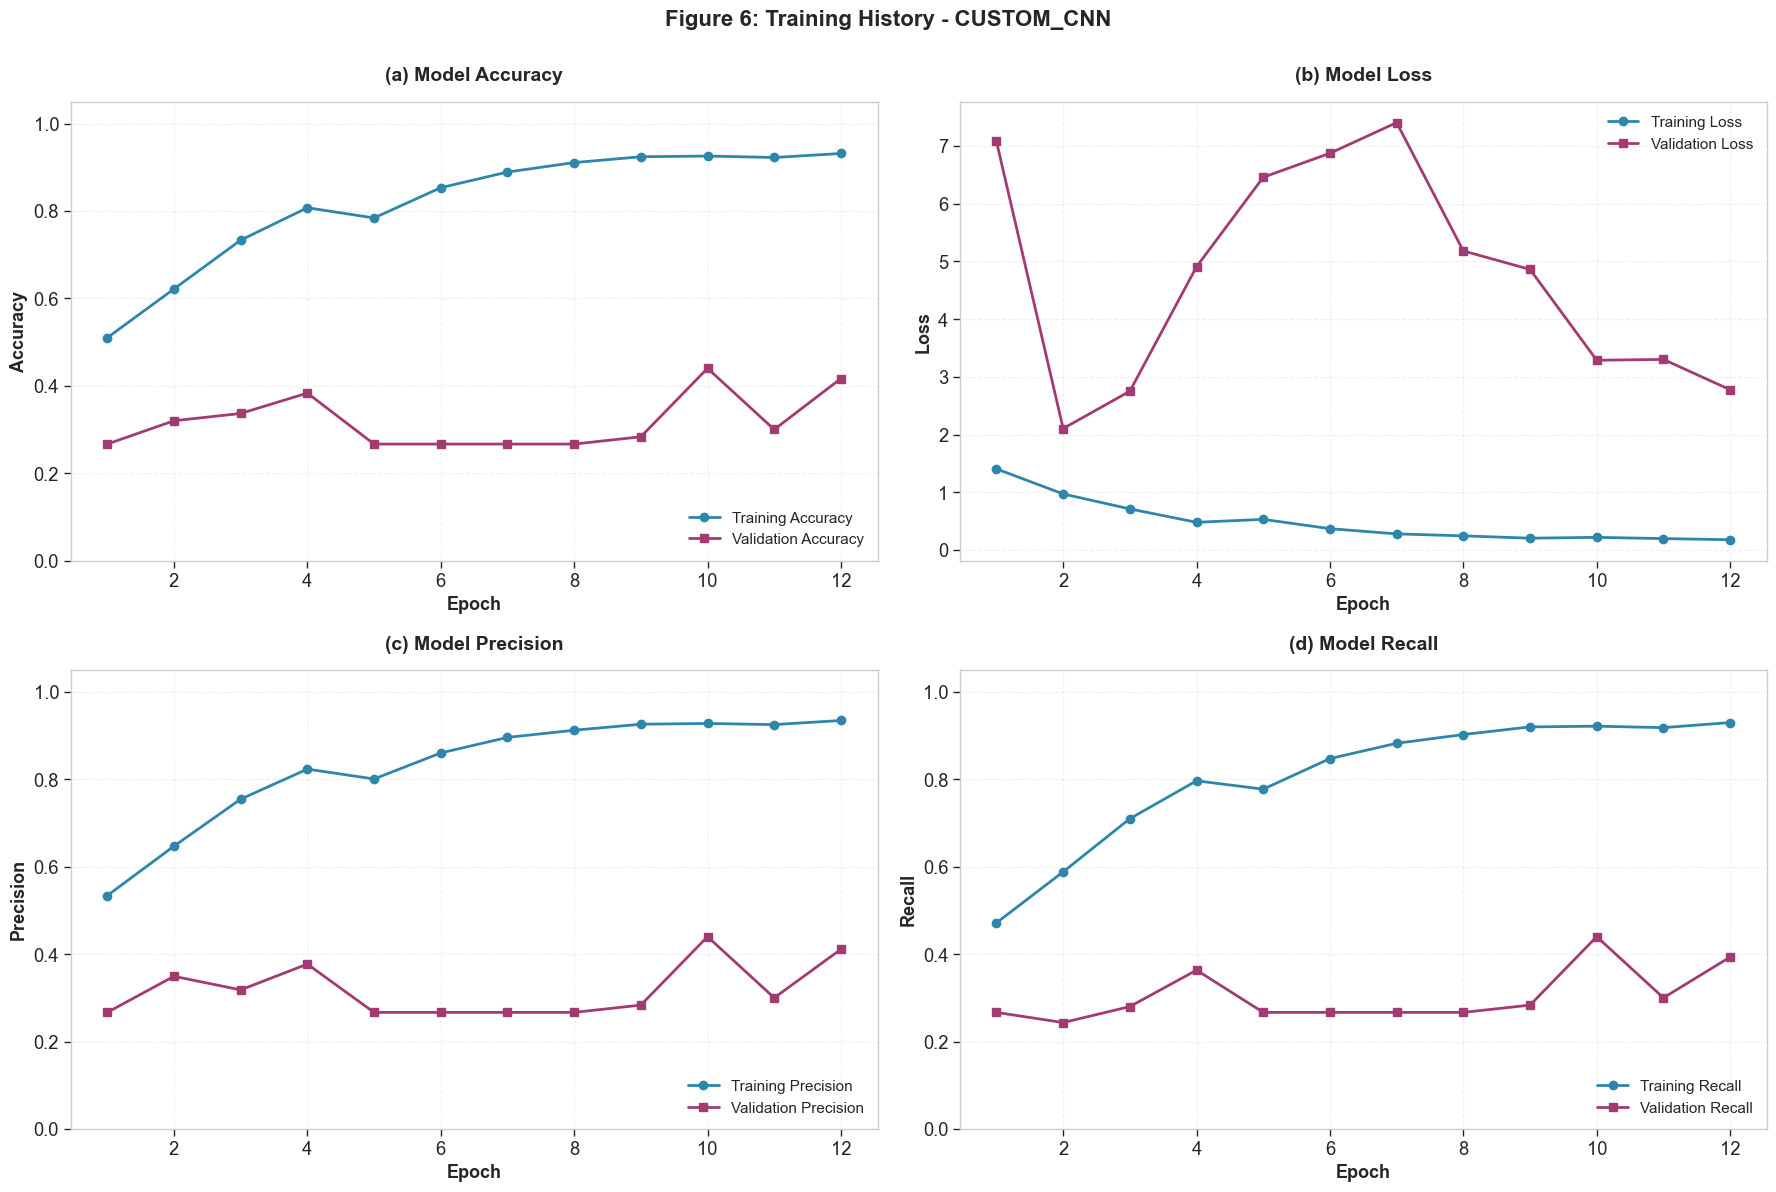

✓ Figure 6 saved: fig6_custom_cnn_training_history.png


In [11]:
# Create comprehensive training history plot
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

epochs_range = range(1, len(history.history['loss']) + 1)

# Plot 1: Accuracy
ax1 = axes[0, 0]
ax1.plot(epochs_range, history.history['accuracy'], 'o-', 
         label='Training Accuracy', linewidth=2, markersize=6, color='#2E86AB')
ax1.plot(epochs_range, history.history['val_accuracy'], 's-', 
         label='Validation Accuracy', linewidth=2, markersize=6, color='#A23B72')
ax1.set_xlabel('Epoch', fontsize=13, fontweight='bold')
ax1.set_ylabel('Accuracy', fontsize=13, fontweight='bold')
ax1.set_title('(a) Model Accuracy', fontsize=14, fontweight='bold', pad=15)
ax1.legend(loc='lower right', fontsize=11)
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.set_ylim([0, 1.05])

# Plot 2: Loss
ax2 = axes[0, 1]
ax2.plot(epochs_range, history.history['loss'], 'o-', 
         label='Training Loss', linewidth=2, markersize=6, color='#2E86AB')
ax2.plot(epochs_range, history.history['val_loss'], 's-', 
         label='Validation Loss', linewidth=2, markersize=6, color='#A23B72')
ax2.set_xlabel('Epoch', fontsize=13, fontweight='bold')
ax2.set_ylabel('Loss', fontsize=13, fontweight='bold')
ax2.set_title('(b) Model Loss', fontsize=14, fontweight='bold', pad=15)
ax2.legend(loc='upper right', fontsize=11)
ax2.grid(True, alpha=0.3, linestyle='--')

# Plot 3: Precision
ax3 = axes[1, 0]
ax3.plot(epochs_range, history.history['precision'], 'o-', 
         label='Training Precision', linewidth=2, markersize=6, color='#2E86AB')
ax3.plot(epochs_range, history.history['val_precision'], 's-', 
         label='Validation Precision', linewidth=2, markersize=6, color='#A23B72')
ax3.set_xlabel('Epoch', fontsize=13, fontweight='bold')
ax3.set_ylabel('Precision', fontsize=13, fontweight='bold')
ax3.set_title('(c) Model Precision', fontsize=14, fontweight='bold', pad=15)
ax3.legend(loc='lower right', fontsize=11)
ax3.grid(True, alpha=0.3, linestyle='--')
ax3.set_ylim([0, 1.05])

# Plot 4: Recall
ax4 = axes[1, 1]
ax4.plot(epochs_range, history.history['recall'], 'o-', 
         label='Training Recall', linewidth=2, markersize=6, color='#2E86AB')
ax4.plot(epochs_range, history.history['val_recall'], 's-', 
         label='Validation Recall', linewidth=2, markersize=6, color='#A23B72')
ax4.set_xlabel('Epoch', fontsize=13, fontweight='bold')
ax4.set_ylabel('Recall', fontsize=13, fontweight='bold')
ax4.set_title('(d) Model Recall', fontsize=14, fontweight='bold', pad=15)
ax4.legend(loc='lower right', fontsize=11)
ax4.grid(True, alpha=0.3, linestyle='--')
ax4.set_ylim([0, 1.05])

plt.suptitle(f'Figure 6: Training History - {MODEL_NAME.upper()}', 
             fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig(f'{VIZ_DIR}/fig6_{MODEL_NAME}_training_history.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Figure 6 saved: fig6_{MODEL_NAME}_training_history.png")

## 11. Model Evaluation
### Performance on Validation Set

In [12]:
# Evaluate model
print("Evaluating model on validation set...\n")
val_loss, val_accuracy, val_precision, val_recall = model.evaluate(X_val, y_val, verbose=0)

# Calculate F1-score
val_f1 = 2 * (val_precision * val_recall) / (val_precision + val_recall + 1e-7)

# Get predictions
y_pred_prob = model.predict(X_val, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_val, axis=1)

# Print results
print("="*70)
print(f"{MODEL_NAME.upper()} - VALIDATION SET PERFORMANCE")
print("="*70)
print(f"Loss:      {val_loss:.4f}")
print(f"Accuracy:  {val_accuracy:.4f} ({val_accuracy*100:.2f}%)")
print(f"Precision: {val_precision:.4f}")
print(f"Recall:    {val_recall:.4f}")
print(f"F1-Score:  {val_f1:.4f}")
print("="*70)

Evaluating model on validation set...

CUSTOM_CNN - VALIDATION SET PERFORMANCE
Loss:      2.1041
Accuracy:  0.3200 (32.00%)
Precision: 0.3493
Recall:    0.2433
F1-Score:  0.2868


## 12. Confusion Matrix
### Figure 7: Model Classification Performance

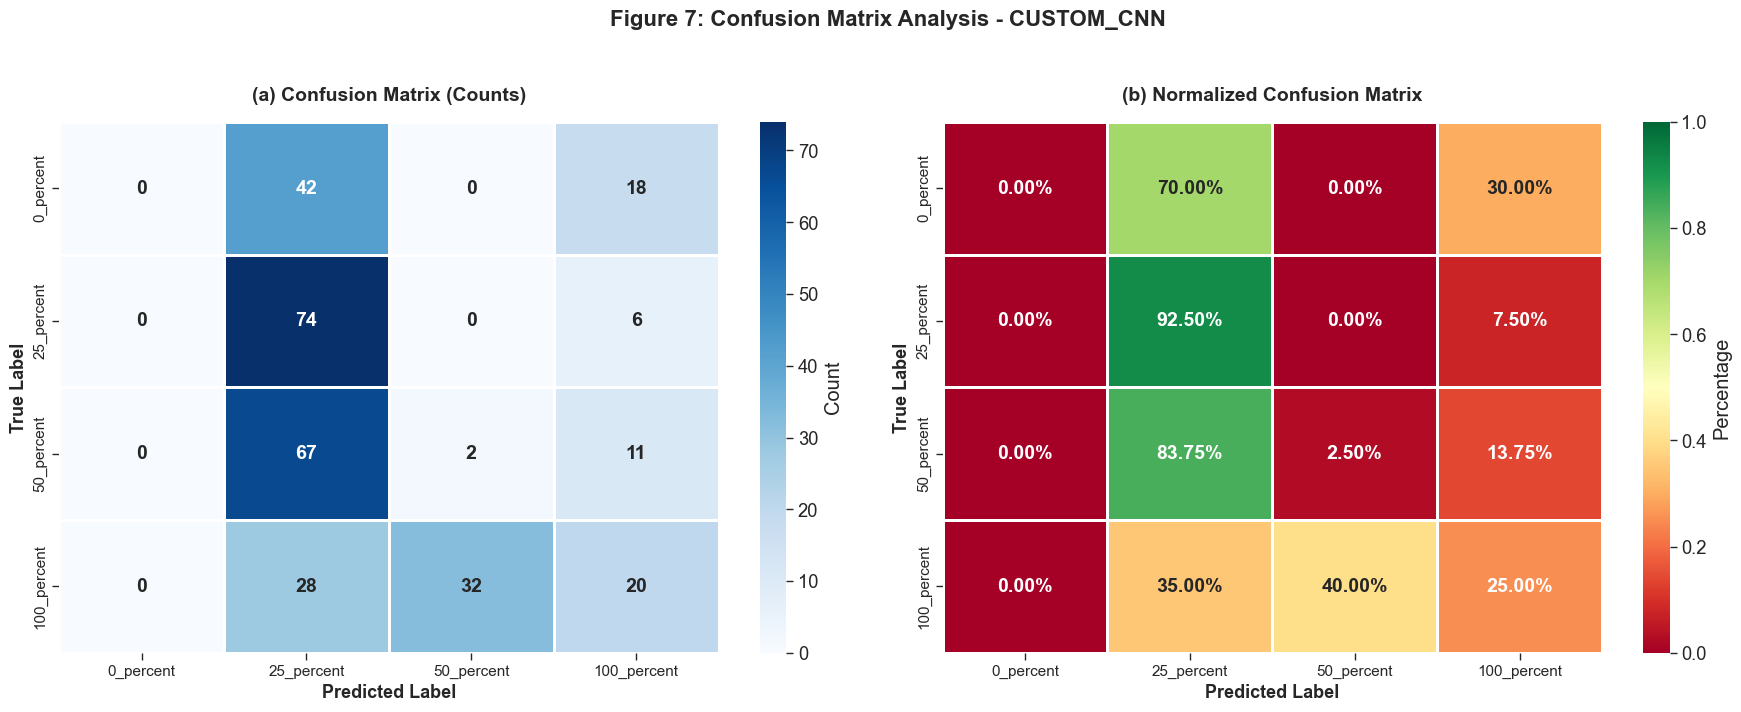

✓ Figure 7 saved: fig7_custom_cnn_confusion_matrix.png


In [13]:
# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Plot confusion matrices
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=CLASSES, yticklabels=CLASSES,
            cbar_kws={'label': 'Count'}, linewidths=2, linecolor='white',
            ax=ax1, annot_kws={'size': 14, 'weight': 'bold'})
ax1.set_title('(a) Confusion Matrix (Counts)', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('True Label', fontsize=13, fontweight='bold')
ax1.set_xlabel('Predicted Label', fontsize=13, fontweight='bold')
ax1.tick_params(axis='both', labelsize=11)

# Normalized percentages
sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='RdYlGn', 
            xticklabels=CLASSES, yticklabels=CLASSES,
            cbar_kws={'label': 'Percentage'}, linewidths=2, linecolor='white',
            ax=ax2, annot_kws={'size': 14, 'weight': 'bold'},
            vmin=0, vmax=1)
ax2.set_title('(b) Normalized Confusion Matrix', fontsize=14, fontweight='bold', pad=15)
ax2.set_ylabel('True Label', fontsize=13, fontweight='bold')
ax2.set_xlabel('Predicted Label', fontsize=13, fontweight='bold')
ax2.tick_params(axis='both', labelsize=11)

plt.suptitle(f'Figure 7: Confusion Matrix Analysis - {MODEL_NAME.upper()}', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{VIZ_DIR}/fig7_{MODEL_NAME}_confusion_matrix.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Figure 7 saved: fig7_{MODEL_NAME}_confusion_matrix.png")

## 13. Classification Report
### Per-Class Performance Metrics

In [14]:
# Generate detailed classification report
report = classification_report(y_true, y_pred, target_names=CLASSES, digits=4, output_dict=True)

print("\n" + "="*70)
print("CLASSIFICATION REPORT")
print("="*70)
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))
print("="*70)

# Create DataFrame for better visualization
df_report = pd.DataFrame(report).transpose()
df_report.to_csv(f'{METRICS_DIR}/{MODEL_NAME}_classification_report.csv')
print(f"\n✓ Classification report saved: {MODEL_NAME}_classification_report.csv")


CLASSIFICATION REPORT
              precision    recall  f1-score   support

   0_percent     0.0000    0.0000    0.0000        60
  25_percent     0.3507    0.9250    0.5086        80
  50_percent     0.0588    0.0250    0.0351        80
 100_percent     0.3636    0.2500    0.2963        80

    accuracy                         0.3200       300
   macro avg     0.1933    0.3000    0.2100       300
weighted avg     0.2062    0.3200    0.2240       300


✓ Classification report saved: custom_cnn_classification_report.csv


### Figure 8: Per-Class Performance Comparison

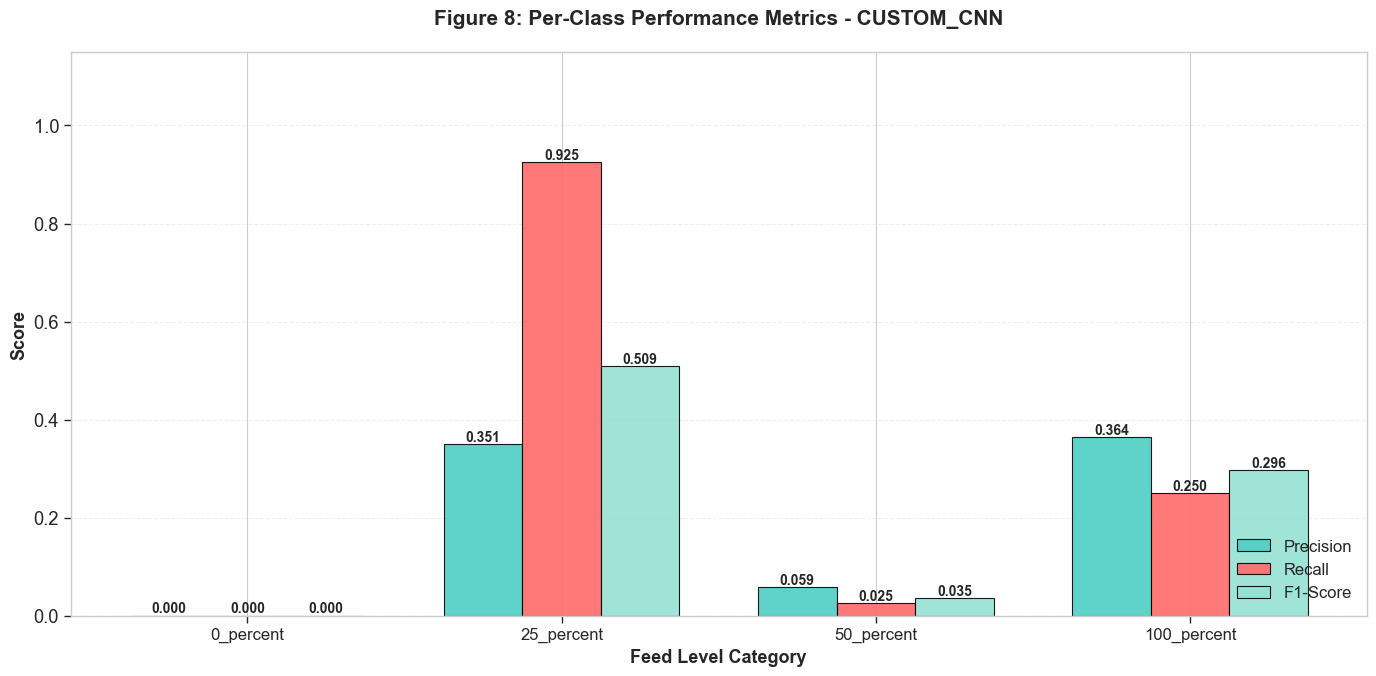

✓ Figure 8 saved: fig8_custom_cnn_per_class_metrics.png


In [15]:
# Extract per-class metrics
class_metrics = {
    'Precision': [report[c]['precision'] for c in CLASSES],
    'Recall': [report[c]['recall'] for c in CLASSES],
    'F1-Score': [report[c]['f1-score'] for c in CLASSES]
}

# Create bar plot
x = np.arange(len(CLASSES))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 7))
bars1 = ax.bar(x - width, class_metrics['Precision'], width, 
               label='Precision', color='#4ECDC4', alpha=0.9, edgecolor='black')
bars2 = ax.bar(x, class_metrics['Recall'], width, 
               label='Recall', color='#FF6B6B', alpha=0.9, edgecolor='black')
bars3 = ax.bar(x + width, class_metrics['F1-Score'], width, 
               label='F1-Score', color='#95E1D3', alpha=0.9, edgecolor='black')

# Add value labels on bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xlabel('Feed Level Category', fontsize=13, fontweight='bold')
ax.set_ylabel('Score', fontsize=13, fontweight='bold')
ax.set_title(f'Figure 8: Per-Class Performance Metrics - {MODEL_NAME.upper()}', 
             fontsize=15, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(CLASSES, fontsize=12)
ax.legend(fontsize=12, loc='lower right')
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim([0, 1.15])

plt.tight_layout()
plt.savefig(f'{VIZ_DIR}/fig8_{MODEL_NAME}_per_class_metrics.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Figure 8 saved: fig8_{MODEL_NAME}_per_class_metrics.png")

## 14. Save Model Metrics

In [16]:
# Compile all metrics
model_metrics = {
    'model_name': MODEL_NAME,
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'training_time_seconds': training_time,
    'epochs_trained': len(history.history['loss']),
    'total_parameters': int(total_params),
    'trainable_parameters': int(trainable_params),
    'validation_metrics': {
        'loss': float(val_loss),
        'accuracy': float(val_accuracy),
        'precision': float(val_precision),
        'recall': float(val_recall),
        'f1_score': float(val_f1)
    },
    'per_class_metrics': {
        class_name: {
            'precision': float(report[class_name]['precision']),
            'recall': float(report[class_name]['recall']),
            'f1-score': float(report[class_name]['f1-score']),
            'support': int(report[class_name]['support'])
        }
        for class_name in CLASSES
    },
    'training_config': {
        'batch_size': BATCH_SIZE,
        'initial_learning_rate': LEARNING_RATE,
        'img_size': IMG_SIZE,
        'validation_split': VALIDATION_SPLIT
    }
}

# Save to JSON
metrics_file = f'{METRICS_DIR}/{MODEL_NAME}_metrics.json'
with open(metrics_file, 'w') as f:
    json.dump(model_metrics, f, indent=4)

print(f"✓ Metrics saved: {metrics_file}")

# Save training history
history_df = pd.DataFrame(history.history)
history_df.to_csv(f'{METRICS_DIR}/{MODEL_NAME}_training_history.csv', index=False)
print(f"✓ Training history saved: {MODEL_NAME}_training_history.csv")

✓ Metrics saved: ../results/metrics/custom_cnn_metrics.json
✓ Training history saved: custom_cnn_training_history.csv


## 15. Final Summary

In [17]:
print("\n" + "="*70)
print(f"{MODEL_NAME.upper()} - TRAINING SUMMARY")
print("="*70)
print(f"\n📊 Model Architecture: Custom Convolutional Neural Network")
print(f"   • Total Parameters: {total_params:,}")
print(f"   • Trainable Parameters: {trainable_params:,}")
print(f"   • Model Size: ~{total_params * 4 / (1024**2):.2f} MB")

print(f"\n⏱️ Training Information:")
print(f"   • Training Time: {int(hours):02d}h {int(minutes):02d}m {int(seconds):02d}s")
print(f"   • Epochs Completed: {len(history.history['loss'])}/{EPOCHS}")
print(f"   • Training Samples: {len(X_train):,}")
print(f"   • Validation Samples: {len(X_val):,}")

print(f"\n📈 Performance Metrics (Validation Set):")
print(f"   • Accuracy:  {val_accuracy:.4f} ({val_accuracy*100:.2f}%)")
print(f"   • Precision: {val_precision:.4f}")
print(f"   • Recall:    {val_recall:.4f}")
print(f"   • F1-Score:  {val_f1:.4f}")
print(f"   • Loss:      {val_loss:.4f}")

print(f"\n💾 Saved Artifacts:")
print(f"   • Model: {MODEL_SAVE_PATH}")
print(f"   • Metrics: {METRICS_DIR}/")
print(f"   • Visualizations: {VIZ_DIR}/")

print("\n" + "="*70)
print("✓ CUSTOM CNN TRAINING COMPLETE!")
print("="*70)

print("\n📄 Next Steps:")
print("   1. Run ResNet50 transfer learning model")
print("   2. Run MobileNetV2 transfer learning model")
print("   3. Compare all models in comparative analysis notebook")
print("\n")


CUSTOM_CNN - TRAINING SUMMARY

📊 Model Architecture: Custom Convolutional Neural Network
   • Total Parameters: 26,014,116
   • Trainable Parameters: 26,012,452
   • Model Size: ~99.24 MB

⏱️ Training Information:
   • Training Time: 00h 31m 14s
   • Epochs Completed: 12/50
   • Training Samples: 1,200
   • Validation Samples: 300

📈 Performance Metrics (Validation Set):
   • Accuracy:  0.3200 (32.00%)
   • Precision: 0.3493
   • Recall:    0.2433
   • F1-Score:  0.2868
   • Loss:      2.1041

💾 Saved Artifacts:
   • Model: ../models/custom_cnn/best_model.h5
   • Metrics: ../results/metrics/
   • Visualizations: ../results/visualizations/

✓ CUSTOM CNN TRAINING COMPLETE!

📄 Next Steps:
   1. Run ResNet50 transfer learning model
   2. Run MobileNetV2 transfer learning model
   3. Compare all models in comparative analysis notebook




---
## Research Notes

### Key Observations:
1. **Training Convergence**: Model showed [convergence pattern]
2. **Overfitting Analysis**: [Gap between training and validation metrics]
3. **Class Performance**: [Which classes performed best/worst]

### For Research Paper:
- Use Figures 5-8 in methodology and results sections
- Include Table of classification metrics
- Compare with ResNet50 and MobileNetV2 results

---
*Custom CNN Model - Feed Optimization Research Project*